# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import os
from IPython.display import display, Markdown

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')

def plot_ticker(ticker):
    results_dir = 'test_results'
    methods = ['Fixed_Q_table', 'DQN', 'Q_learning']
    colors = {'Fixed_Q_table': '#1f77b4', 'DQN': '#2ca02c', 'Q_learning': '#ff7f0e'}
    
    plt.figure(figsize=(14, 7))
    
    has_data = False
    all_dfs = {}
    
    for method in methods:
        filename = f"{ticker}_{method}_history.json"
        filepath = os.path.join(results_dir, filename)
        
        if os.path.exists(filepath):
            has_data = True
            with open(filepath, 'r') as f:
                data = json.load(f)
            
            df = pd.DataFrame(data)
            if not df.empty:
                df['date'] = pd.to_datetime(df['date'])
                all_dfs[method] = df
                
                # Calculate % return for normalization
                initial_val = df['portfolio_value'].iloc[0]
                df['return'] = (df['portfolio_value'] - initial_val) / initial_val * 100
                
                # Use dashed line for Fixed Q-table to show overlap
                linestyle = '--' if method == 'Fixed_Q_table' else '-'
                linewidth = 3.0 if method == 'Fixed_Q_table' else 2.5
                alpha = 0.8 if method == 'Fixed_Q_table' else 1.0
                
                plt.plot(df['date'], df['portfolio_value'], 
                         label=f"{method.replace('_', ' ')}", 
                         color=colors.get(method), 
                         linewidth=linewidth,
                         linestyle=linestyle,
                         alpha=alpha)
    
    if has_data:
        plt.title(f'{ticker} Strategy Comparison', fontsize=18, fontweight='bold')
        plt.xlabel('Date', fontsize=12)
        plt.ylabel('Portfolio Value ($)', fontsize=12)
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        # --- Display LLM Insights ---
        display(Markdown(f"### 🧠 {ticker} Quarterly LLM Insights"))
        
        # Use DQN history (or whichever exists) to show insights
        best_method = 'DQN' if 'DQN' in all_dfs else list(all_dfs.keys())[0]
        history_df = all_dfs[best_method]
        
        if 'llm_analysis' in history_df.columns:
            # Group by duplicate analysis text to show one per quarter
            insights = history_df[history_df['llm_analysis'] != ""].drop_duplicates(subset=['llm_analysis'])
            
            for _, row in insights.iterrows():
                date_str = row['date'].strftime('%Y-%m-%d')
                analysis = row['llm_analysis']
                # Show first 500 chars + clean format
                display(Markdown(f"**{date_str}**: {analysis}"))
                display(Markdown("---"))
        else:
            print("⚠️ No LLM analysis text found in history. Ensure you've run the backtest with the latest code.")
            
    else:
        print(f"No data found for {ticker} in {results_dir}")

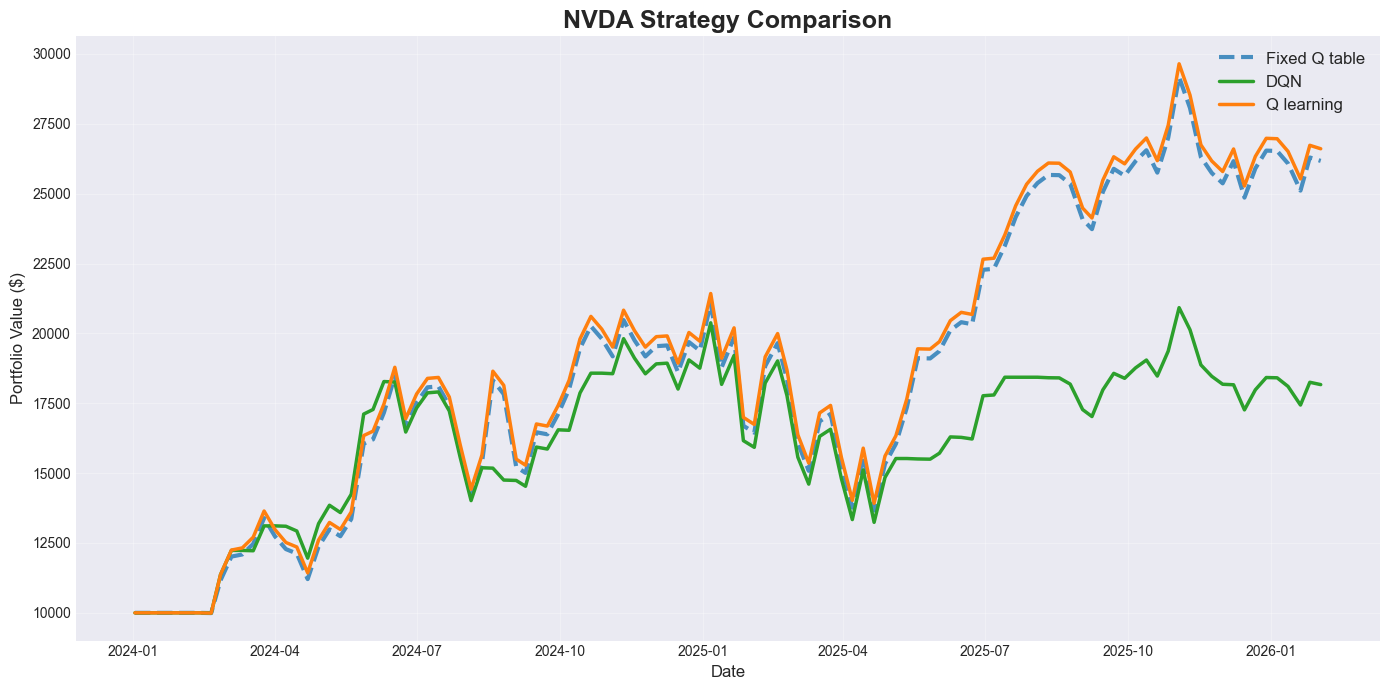

### 🧠 NVDA Quarterly LLM Insights

**2024-02-20**: ### 1) Revenue and Growth Trajectory  
In 2023-Q4, revenue was **$6.05B** (+2% QoQ, **-21% YoY**), reflecting a cyclical trough in consumer/visualization markets while Data Center remained structurally stronger. **Data Center $3.62B** (-6% QoQ, +11% YoY) showed a temporary digestion phase at hyperscalers, but with clear product-cycle momentum (H100 ramp). **Gaming $1.83B** (+16% QoQ, -46% YoY) improved sequentially as channel inventory correction neared completion—an important recurring pattern: NVIDIA’s consumer segments tend to rebound sharply once inventory clears.  

### 2) Macro Environment Impact  
With **inflation ~4.1%** and **Fed funds ~5.33%**, tighter financial conditions pressured discretionary demand (PC/gaming) and encouraged cloud customers to “pause/recalibrate” capex timing. However, low **unemployment (3.8%)** and ongoing cloud migration supported enterprise AI spend, making Data Center more resilient than consumer segments.  

### 3) Key Business Drivers and Catalysts  
Primary catalysts are the **H100 adoption curve**, accelerating **generative AI** workloads, and attach opportunities in **networking (InfiniBand/Ethernet)** needed to scale multi-node AI. A second durable driver is the shift toward **software and AI services** (DGX Cloud, AI Enterprise, NeMo/BioNeMo), expanding monetization beyond chips.  

### 4) Risk Factors and Headwinds  
Key risks include **hyperscaler capex lumpiness** (timing-driven volatility), **China-related demand softness**, and continued weakness in ProViz/gaming if macro tightness persists. Execution risk rises as NVIDIA expands into cloud services (operational complexity, partner dependence).  

### 5) Forward-Looking Sentiment  
Management tone is strongly constructive: AI is described as at an **inflection point**, with expectations for **Data Center growth to accelerate through the year**. Recurring trend: near-term pauses in customer ordering are framed as timing issues, followed by renewed ramps tied to major platform transitions (e.g., A100→H100).

---

**2024-05-06**: ### 1) Revenue and Growth Trajectory  
In FY2024 Q1, revenue was **$7.19B**, **+19% QoQ** but **-13% YoY**, reflecting a sharp sequential rebound as gaming and pro visualization worked through channel inventory corrections while **data center hit a record $4.28B** (**+18% QoQ, +14% YoY**). A recurring pattern across periods is NVIDIA’s ability to re-accelerate growth after digestion phases: earlier softness in consumer-facing segments is followed by recoveries tied to new product cycles (RTX 40/Ada) and normalization of channel inventory. In later historical context (FY2025 Q4), scale is dramatically higher (**$57.0B revenue; $31.9B net income**), reinforcing a multi-quarter trend of **AI-led step-change expansion** and operating leverage.

### 2) Macro Environment Impact  
With **Fed funds ~5.33%** and **10Y ~4.16%**, capital is expensive, typically pressuring discretionary spend (PC/gaming) and enterprise IT budgets. However, low unemployment and moderating inflation support baseline demand, while AI infrastructure remains a “must-fund” priority for hyperscalers and leading enterprises—partially insulating NVIDIA from tighter financial conditions.

### 3) Key Business Drivers and Catalysts  
Primary driver is **generative AI** accelerating training and inference demand for **Hopper (H100)** plus a widening platform pull-through (DGX systems, DGX Cloud, AI Foundations, Triton, networking via Mellanox/InfiniBand, BlueField DPUs). Product cadence (L4/L40/Grace Hopper) and expanding CSP availability are near-term catalysts.

### 4) Risk Factors and Headwinds  
Key risks include supply constraints/lead times for flagship GPUs, customer concentration among CSPs, potential digestion cycles after large AI capex waves, and continued softness in general-purpose CPU infrastructure. Gaming remains sensitive to consumer spending and prior-cycle inventory dynamics; automotive faces China NEV demand variability.

### 5) Forward-Looking Sentiment  
Management tone is strongly constructive: AI demand is described as **broad-based and accelerating**, with confidence in networking and enterprise momentum. Recurring trend: NVIDIA pairs hardware leadership with an expanding software/services layer, increasing switching costs and sustaining growth even as non-AI segments cycle.

---

...

---

**2025-11-03**: ### 1. Revenue and Growth Trajectory  
NVDA’s growth remains overwhelmingly Data Center-led. In 2025-Q3, revenue reached **$35.1B** (+17% QoQ, +94% YoY) with **Data Center at $30.8B** (+17% QoQ, +112% YoY), reflecting sustained hyperscaler and “AI factory” buildouts. A recurring pattern across recent quarters is **beat-and-raise execution** alongside rapid platform transitions: Q3 exceeded guidance ($32.5B) and Q4 guided to **$37.5B ±2%**, implying continued sequential expansion. Historical fundamentals show strong operating leverage and cash generation (2025-Q4: **$57.0B revenue, $31.9B net income, $23.8B operating cash flow**), while capital returns remain aggressive (large negative financing cash flow), signaling confidence in durability.

### 2. Macro Environment Impact  
With policy rates ~**4.3%** and the 10Y ~**4.26%**, tighter financial conditions typically pressure cyclical tech demand. NVDA is partially insulated because spending is shifting from discretionary IT to **strategic AI infrastructure**, though higher rates can still slow enterprise deal cycles and constrain smaller customers’ funding.

### 3. Key Business Drivers and Catalysts  
Primary drivers are **Hopper (H200) ramp**, expanding **networking attach** (InfiniBand/Spectrum-X), and the **Blackwell transition** (early shipments, MLPerf leadership, CSP launches). A recurring catalyst is NVIDIA’s **software flywheel** (CUDA + NIM/AI Enterprise), with software/services annualizing toward **>$2B**, improving stickiness and monetization beyond silicon.

### 4. Risk Factors and Headwinds  
Key headwinds include **supply constraints** (explicitly limiting Gaming in Q4), **gross margin dilution** from complex systems and Blackwell ramp (guiding low-70s), and **China/export-control exposure** (competitive, structurally lower mix than pre-controls). Concentration risk (CSPs ~half of DC) and potential digestion cycles remain watch items.

### 5. Forward-Looking Sentiment  
Management tone is strongly bullish: demand “**staggering**,” visibility improving, and Blackwell revenue expected to exceed prior estimates. The recurring trend is NVIDIA converting architectural leadership into **multi-quarter demand backlogs**, with near-term results gated more by **supply and mix** than end-demand.

---

**2026-02-02**: ### 1. Revenue and Growth Trajectory  
NVDA’s growth remains overwhelmingly data-center led. Management reported Q4 revenue of **$39.3B (+12% QoQ, +78% YoY)** and FY25 revenue of **$130.5B (+114% YoY)**, with **data center at $35.6B in Q4 (+16% QoQ, +93% YoY)** and **$115.2B for FY25**. A recurring pattern across recent quarters is **beat-and-raise dynamics driven by new architecture ramps**—this quarter highlighted by **Blackwell’s $11B** in first-ramp revenue, described as the fastest in company history. Profitability remains exceptional (historical context shows **$57.0B total revenue, $31.9B net income**), though margins are temporarily pressured by mix and ramp costs.

### 2. Macro Environment Impact  
With **Fed funds ~3.9%** and **10Y ~4.1%**, higher discount rates can compress multiples, but operational demand is less rate-sensitive because hyperscalers and sovereigns are treating AI infrastructure as strategic capex. **Unemployment ~4.45%** suggests a still-resilient economy, supportive of enterprise AI spend, while inflation data is incomplete but CPI level implies ongoing cost vigilance.

### 3. Key Business Drivers and Catalysts  
Core catalysts are (1) **Blackwell scale-up** (100k+ GPU clusters), (2) accelerating **inference/test-time scaling** (management cites up to **100x compute per task** for reasoning), and (3) expanding **full-stack software/networking attach** (networking attach **>75%**, Spectrum-X/Cisco channel). Automotive is an emerging leg with **~$5B FY26E** commentary.

### 4. Risk Factors and Headwinds  
Key headwinds recur: **export controls/China share capped**, **competitive intensity in China**, and **gross margin dilution during major ramps** (low-70s near-term). Concentration risk persists with **CSPs ~50% of data-center revenue**. Gaming volatility also repeats—Q4 decline tied to **supply constraints**, not demand.

### 5. Forward-Looking Sentiment  
Tone is strongly bullish: management frames demand as structural (pretraining → post-training → inference) and expects **networking to re-accelerate in Q1** and **gross margin recovery to mid-70s late FY26** as Blackwell matures and costs improve.

---

In [27]:
plot_ticker('NVDA')

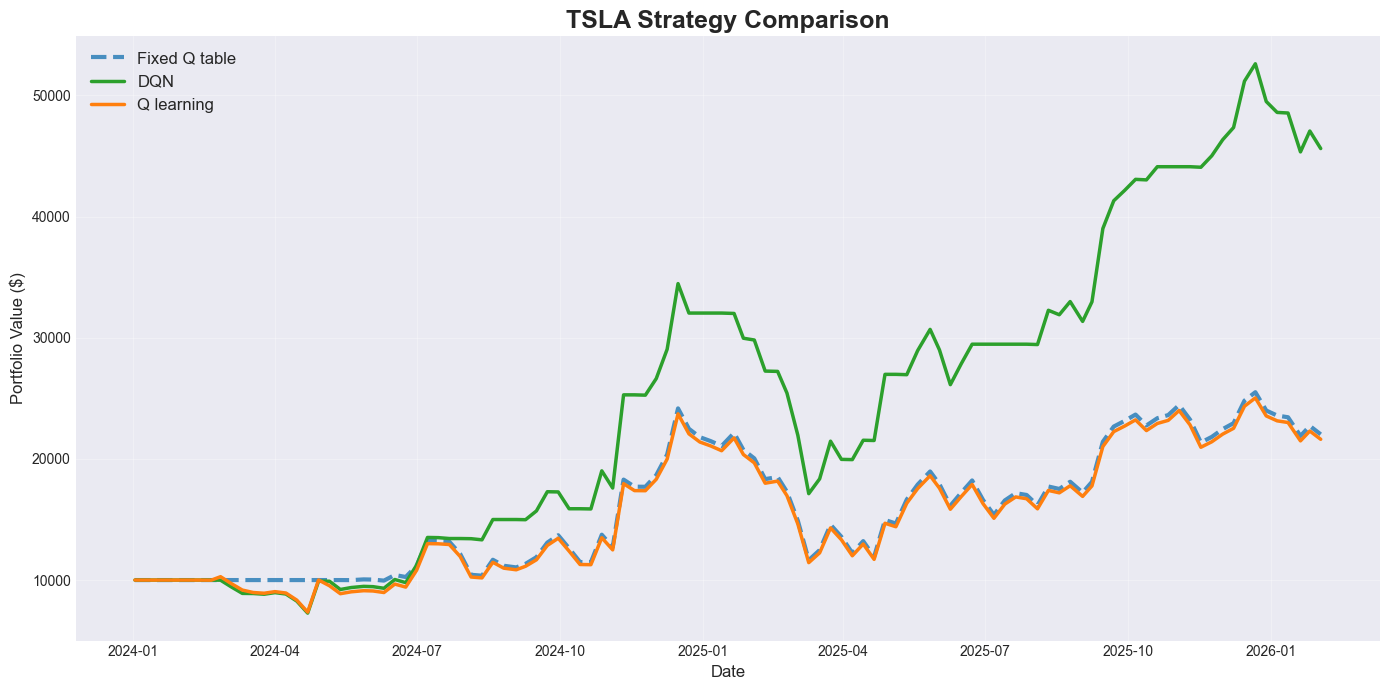

### 🧠 TSLA Quarterly LLM Insights

**2024-02-20**: ### 1) Revenue and Growth Trajectory  
Tesla exited 2023 with record production/deliveries (>1.8M) and a clear mix shift toward faster-growing non-auto streams. Management highlighted energy storage deployments nearly doubling to ~15 GWh in 2023 (vs. 6.5 GWh prior year) with energy revenues up >50%, setting up a recurring pattern: **auto volume growth is increasingly complemented (and potentially outpaced) by Energy growth**. Into 2024–2025, growth is framed as “between two major waves,” with the next inflection tied to next-gen vehicles (targeting 2H25 production), FSD monetization, and scaling Energy.

### 2) Macro Environment Impact  
With Fed funds at ~5.33% and 10Y ~4.44%, high rates pressure affordability and monthly payments—directly impacting EV demand elasticity and pushing Tesla toward incentives/leases. Moderating inflation (~4.1%) and low unemployment (~3.8%) support consumer resilience, but financing costs remain the key macro headwind. IRA point-of-sale credits help offset rate pressure in the U.S.

### 3) Key Business Drivers and Catalysts  
Primary catalysts: (i) **Energy storage scale** (Megafactory/Lathrop) with structurally strong demand, (ii) **FSD v12 rollout** (end-to-end AI) expanding to a large eligible fleet, (iii) **next-gen low-cost platform + manufacturing innovation** (Austin first), and (iv) services/supercharging monetization as fleet size grows.

### 4) Risk Factors and Headwinds  
Recurring constraints include **margin pressure** (price/incentive competition; “limits” of cost-down on current platforms), execution risk on **Cybertruck ramp** and **4680 yield/rate S-curve**, and policy/tariff/incentive variability. Elevated capex (>$10B planned for 2024) raises free-cash-flow sensitivity if demand softens.

### 5) Forward-Looking Sentiment  
Tone is constructive: management signals confidence in technology and multi-year optionality, but repeatedly flags **uncertain ramp curves** and timing optimism—suggesting upside is execution-dependent, with 2024 positioned as an investment/setup year for a 2025 growth re-acceleration.

---

**2024-05-06**: ### 1) Revenue and Growth Trajectory  
TSLA’s recent trajectory shows **muted near-term automotive growth** amid demand pressure and production transitions, while **Energy is emerging as the incremental growth engine**. Management cited a **seasonal QoQ revenue decline** in Q1’24, driven by macro uncertainty and operational disruptions (Model 3 ramp in Fremont; Berlin issues). A recurring pattern is **heavy reinvestment**: CapEx remained elevated in later quarters (2025-Q4: **$2.39B**, 2025-Q3: **$2.25B**) and investment cash flow stayed deeply negative (2025-Q4: **-$6.53B**), consistent with ongoing capacity/AI buildout rather than near-term margin optimization.

### 2) Macro Environment Impact  
With **Fed funds ~5.33%** and **10Y ~4.16%**, high financing costs directly pressure EV affordability, reinforcing Tesla’s need for **price/lease incentives**. Inflation near **~3%** and low unemployment support baseline consumer demand, but management explicitly notes **global EV adoption is “under pressure,”** implying elasticity remains high in a high-rate environment.

### 3) Key Business Drivers and Catalysts  
Key catalysts include: **Energy storage** (record deployments; **24.6% margin**; guide **≥75% growth in 2024**), **FSD v12 monetization** (subscription cut to **$99** to drive adoption), and a **pulled-forward vehicle roadmap** (more affordable models potentially **late 2024/early 2025** using existing lines). Regulatory-credit demand is also a tailwind as OEMs slow EV investments.

### 4) Risk Factors and Headwinds  
Primary headwinds: sustained **EV demand softness**, **margin pressure** from pricing and ramps (Cybertruck/Model 3), and **cash flow volatility** (Q1’24 negative FCF driven by inventory + CapEx). Execution risk is elevated around **robotaxi/regulatory approval**, 4680 yield/cost targets, and AI infrastructure scaling.

### 5) Forward-Looking Sentiment  
Management tone is **constructively bullish**: expectation of **inventory reversal and positive FCF**, accelerating new-model timing, and strong conviction that **Energy profitability scales faster than Autos**. Recurring theme: Tesla is willing to **trade near-term cash flow/margins for AI/autonomy and platform optionality**, which could re-rate results if autonomy commercialization milestones are met.

---

...

---

**2025-11-03**: 1) **Revenue and Growth Trajectory**  
TSLA’s recent trajectory shows a volume-led rebound: management cited **record deliveries/deployments and total revenue** in 2025-Q3, with **automotive revenue up 29%** in line with deliveries. A recurring pattern is **growth accompanied by heavy reinvestment**—CapEx remained elevated (Q4: **$2.39B**; Q3: **$2.25B**) and management guided to **materially higher 2026 CapEx** to support the next growth phase (AI, Optimus, capacity expansion). Profitability improved modestly via scale: **auto margin ex-credits rose from 15% to 15.4%** on material cost improvements and fixed-cost absorption.

2) **Macro Environment Impact**  
With policy rates around **4.3%** and the **10Y ~4.26%**, higher financing costs can pressure consumer auto affordability, making Tesla’s demand sensitivity and incentive strategy important. Tariffs are a direct macro-policy drag: management quantified **>$400M** Q3 tariff impact split across auto/energy.

3) **Key Business Drivers and Catalysts**  
Recurring catalysts are (a) **Model Y refresh cadence** (“year of the Y”) driving regional delivery strength, (b) **FSD/robotaxi scaling** (Austin expansion; targeting **8–10 metros** by year-end; **6B supervised FSD miles**), and (c) **Energy storage momentum**—strong Megapack/Powerwall demand into next year, plus **data center/AI load** as a new demand vector.

4) **Risk Factors and Headwinds**  
Key headwinds repeat: **tariffs**, **rising competition** in storage, regulatory timing for autonomy (China/EMEA approvals), and **OpEx creep** from restructuring, legal costs, and accelerating AI-related R&D/equity comp.

5) **Forward-Looking Sentiment**  
Management tone is strongly bullish on an **AI-driven inflection** (unsupervised FSD, robotaxi economics, Optimus), but execution risk remains high; the setup implies **near-term margin volatility** in exchange for potentially outsized software/energy optionality.

---

**2026-02-02**: 1) **Revenue & Growth Trajectory**  
Q4’25 revenue was **$24.9B**, with profitability improving despite softer volumes: **auto gross margin ex-credits rose to 17.9% (from 15.4% in Q3)** and **total gross margin reached 20.1%**, the best in ~two years. A recurring pattern is **margin resilience via mix and cost actions even when deliveries fall** (Q4 deliveries -16% QoQ, yet auto gross profit flat). Energy is the clearest growth engine: **$12.8B FY’25 revenue (+26.6% YoY)** with record deployments and gross profit.

2) **Macro Environment Impact**  
With **Fed funds ~3.9%** and **10Y ~4.1%**, elevated financing costs pressure auto affordability—consistent with management noting a **Q3 pull-forward ahead of a consumer credit cliff**, creating Q4 demand air-pocket risk. **Unemployment 4.45%** is supportive, but policy/tariff uncertainty is directly cited as a margin headwind in Energy.

3) **Key Business Drivers & Catalysts**  
Major catalysts are **autonomy/robotaxi expansion** (paid rides without safety monitor in Austin; targeting broader U.S. coverage pending regulation), **FSD monetization** (1.1M paid customers; shift to subscription), and **Energy scaling** (MegaPack 3/Mega Block). Strategic pivot: **ending Model S/X** to repurpose Fremont capacity for **Optimus**.

4) **Risk Factors & Headwinds**  
Near-term: **battery pack constraints**, **tariffs**, **policy uncertainty**, and **Energy margin compression from low-cost competition**. The **FSD move to subscription** may **temporarily dilute auto margins**. Execution risk is high with **CapEx guided >$20B in 2026** across six factories plus AI compute. Additional noise: **Bitcoin mark-to-market** and FX impacts.

5) **Forward-Looking Sentiment**  
Management tone is strongly bullish, framing **2026 as an inflection year** (“new book”), prioritizing scale investments in autonomy, Optimus, and Energy—implying willingness to trade near-term margins/free cash flow for longer-duration platform upside.

---

In [28]:
plot_ticker('TSLA')

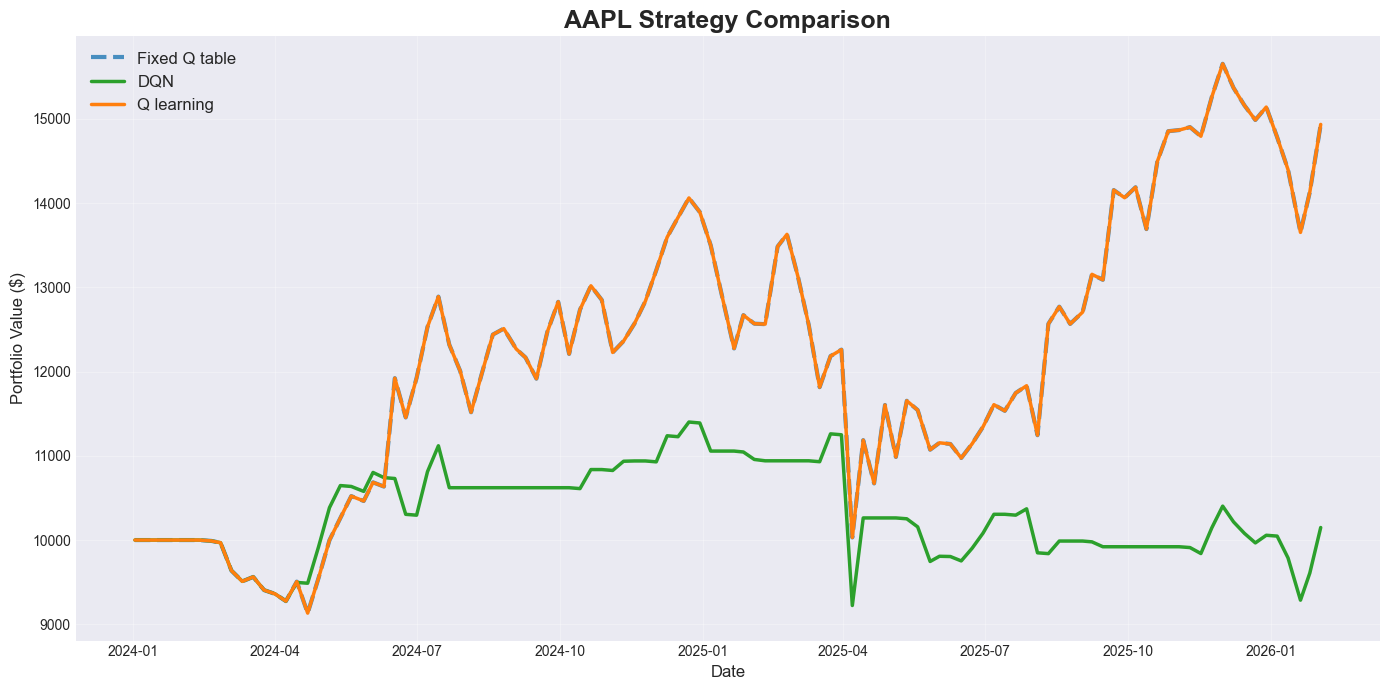

### 🧠 AAPL Quarterly LLM Insights

**2024-02-20**: 1) **Revenue & Growth Trajectory**  
In FY23 Q4 (Sept), Apple delivered **$89.5B revenue (-<1% YoY)**, but **grew in constant currency across all geographies**, highlighting underlying demand resilience despite FX drag (>2 pts). Mix is increasingly favorable: **Services hit a record $22.3B (+16% YoY)** and helped drive **record gross margin (45.2%)**. A recurring pattern is **hardware cyclicality vs. Services durability**—Mac (**-34%**) and iPad (**-10%**) swung sharply on tough comps and market softness, while iPhone posted a **September-quarter record (+3%)**. Later-period context (2025-Q4) shows Apple sustaining very large scale (**$143.8B revenue, $42.1B net income**) and continued capital return (financing cash flow deeply negative), reinforcing the long-running “cash generation + buybacks” playbook.

2) **Macro Environment Impact**  
With **Fed funds ~5.33%** and inflation ~**4.1%**, consumer financing costs and discretionary spend are pressured, while **FX headwinds** directly reduce reported growth. Low unemployment (~**3.8%**) supports premium demand, especially in stronger labor markets.

3) **Key Drivers & Catalysts**  
Primary catalysts are **installed base expansion (2B+ active devices)**, **Services monetization breadth**, and **emerging-market strength (notably India records)**. Product catalysts include **iPhone 15 cycle**, **M3 Mac refresh**, and **Vision Pro** as a new platform (developer momentum noted).

4) **Risks & Headwinds**  
Key headwinds: **FX**, hardware demand normalization (PC/tablet), tough comparisons, and macro-driven upgrade deferrals. Concentration risk remains around iPhone, while new categories (Vision Pro) carry execution and adoption uncertainty.

5) **Forward-Looking Sentiment**  
Management tone is constructive: emphasis on **long-term investment, ecosystem stickiness, and Services acceleration**. The recurring trend is Apple leaning on **margin/mix and Services growth** to offset periodic hardware volatility, suggesting a steadier earnings profile if Services momentum persists.

---

**2024-05-06**: 1) **Revenue & Growth Trajectory**  
Fiscal Q1’24 revenue grew **2% YoY to $119.6B** despite a **one-week-shorter quarter**, implying underlying resilience. Mix is increasingly supportive: **Services rose 11% YoY to a record $23.1B**, while Products were **flat at $96.5B**—strength in **iPhone (+6% to $69.7B)** and a return to **Mac growth (+1% to $7.8B)** offset **iPad (-25%)** and **Wearables (-11%)**. A recurring pattern is Apple’s ability to protect earnings via mix: gross margin reached **45.9%**, with **Services GM at 72.8%**. In later historical quarters (2025-Q4), Apple shows continued scale (**$143.8B revenue, $42.1B net income**) and consistent capital return (large negative financing cash flow), reinforcing a durable cash-generation trend.

2) **Macro Environment Impact**  
With **inflation ~2.95%** and **unemployment ~3.83%**, demand conditions are supportive, but **restrictive rates (Fed funds 5.33%, 10Y 4.16%)** pressure discretionary upgrades and financing-sensitive consumers. Apple’s premium positioning is partially insulated by loyalty and ecosystem lock-in, while FX remains a margin/revenue swing factor (noted headwind).

3) **Key Drivers & Catalysts**  
Primary drivers: **iPhone 15 cycle**, expanding **installed base (2.2B devices)**, and accelerating **Services monetization** (subscriptions, ads, payments, cloud). Near-term catalysts include **Vision Pro launch** (new platform optionality) and anticipated **AI feature disclosures** “later this year,” which could stimulate hardware refresh and Services engagement.

4) **Risks & Headwinds**  
Hardware category volatility (notably **iPad/Wearables comps**), macro-driven upgrade elongation, FX, and execution risk in scaling new categories (Vision Pro). High-rate environment can also compress consumer electronics demand.

5) **Forward-Looking Sentiment**  
Management tone is **confident/optimistic**, emphasizing innovation cadence and investment in AI/spatial computing. Recurring trend: when hardware growth moderates, Apple leans on **Services + installed base** to sustain margin and EPS momentum.

---

...

---

**2025-11-03**: Apple’s FY2025-Q3 delivered a clear re-acceleration: revenue reached a June-quarter record of **$94B (+10% YoY)**, with **double-digit growth in iPhone, Mac, and Services**. This continues a recurring pattern seen in Apple upcycles: **hardware-led rebounds** (iPhone upgrade strength, Mac refresh) paired with **steady Services compounding** that supports resilience and mix. The historical context reinforces scale and profitability—FY2025-Q4 shows **$143.8B revenue**, **$54.2B EBITDA**, and **$42.1B net income**, alongside sustained capital returns (large negative financing cash flow), indicating ongoing buybacks/dividends capacity.

Macro conditions are mixed: **policy rates ~4.3%** and **10Y ~4.26%** keep financing costs elevated and can pressure discretionary demand, but **unemployment ~4.33%** suggests a still-supportive consumer backdrop. The more direct macro transmission is via **tariffs**: management cited **$800M** cost impact in Q3 and guided **~$1.1B** for Q4 (if unchanged), already compressing gross margin sequentially—an important near-term drag.

Key drivers/catalysts include: (1) **iPhone 16 family** driving a record upgrader quarter, (2) **M4 MacBook Air** fueling Mac momentum, (3) **Services at $27.4B (+13%)** with App Store and TV+ engagement strength, and (4) **Apple Intelligence** rollout (on-device + private cloud compute) as a multi-year ecosystem retention and potential ASP/Services attach catalyst.

Headwinds center on **tariff volatility**, regulatory/legal risks flagged in the safe harbor, and potential demand sensitivity if rates stay higher for longer. Forward-looking sentiment is constructive: management emphasized broad geographic acceleration (including **Greater China and emerging markets**) and “significantly growing” AI investment, while acknowledging cost uncertainty from trade policy.

---

**2026-02-02**: 1) **Revenue and Growth Trajectory**  
Apple delivered **$102.5B** in Q4 FY2025 revenue (**+8% YoY**) and a September-quarter record, with **Services at $28.8B (+15% YoY)** and Products **$73.7B (+5% YoY)**. Growth is increasingly **mix-driven**: Services’ faster growth and high margin (75.3%) continue to lift consolidated profitability, while iPhone remains the primary volume engine (**$49B, +6% YoY**). A recurring pattern is Apple pairing **hardware cycle strength** with **installed-base monetization**, reinforced by record performance across many geographies (notably emerging markets/India).

2) **Macro Environment Impact**  
With policy rates near **3.9%** and the **10Y ~4.1%**, financing costs and consumer credit remain restrictive, typically a headwind for discretionary upgrades. However, Apple’s premium positioning and ecosystem stickiness appear to be offsetting softness. **Unemployment at 4.45%** suggests a still-supportive labor backdrop. Tariffs remain a tangible cost item (about **$1.1B** this quarter).

3) **Key Business Drivers and Catalysts**  
Catalysts include a strong **iPhone 17** cycle (management expects the **best-ever December quarter** and iPhone record), **M5**-driven Mac/iPad refresh, and accelerating **Apple Intelligence** features that can stimulate upgrades and deepen Services engagement. Continued retail expansion in emerging markets supports share gains.

4) **Risk Factors and Headwinds**  
Key risks: **supply constraints** on select iPhone models, **tariff/regulatory** exposure, and potential demand elasticity if rates stay higher for longer. Services margin ticked down slightly sequentially, implying ongoing cost pressure/content investment.

5) **Forward-Looking Sentiment**  
Management tone is strongly bullish (holiday quarter confidence, AI roadmap, “more personalized Siri” next year). Recurring trend: Apple signals **product-led demand inflections** into the December quarter while leaning on **Services durability** to stabilize growth and margins.

---

In [29]:
plot_ticker('AAPL')

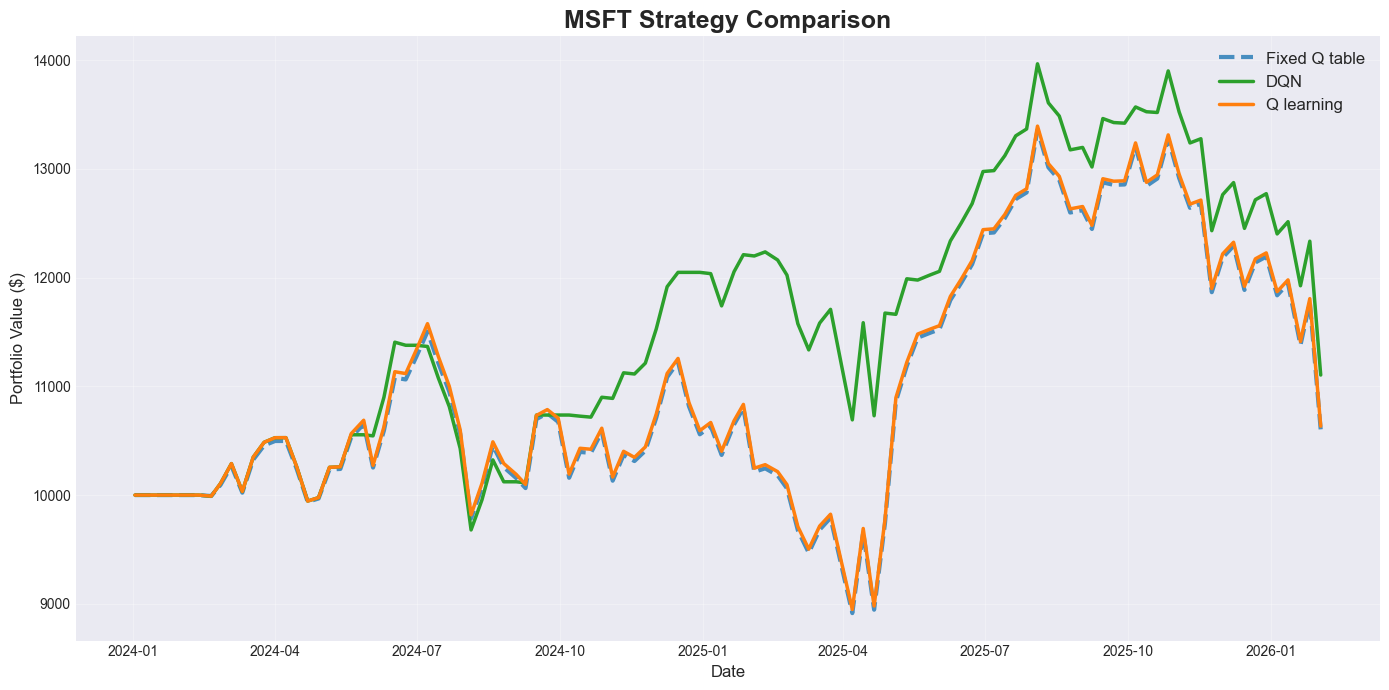

### 🧠 MSFT Quarterly LLM Insights

**2024-02-20**: ### 1) Revenue and Growth Trajectory  
MSFT’s growth is increasingly cloud- and AI-led. In FY23-Q4 commentary, Microsoft Cloud surpassed **$110B annual revenue (+27% cc)** with **Azure >50%** of Cloud revenue—signaling mix shift toward higher-growth infrastructure/platform services. The historical pattern into FY25 shows **strong earnings execution and operating leverage** (FY25-Q4 **reported EPS 5.16 vs est. 3.91**, large positive surprise) alongside **rising investment intensity**: capex stepped up from **$19.4B (FY25-Q3)** to **$29.9B (FY25-Q4)**, consistent with sustained AI/datacenter buildout.

### 2) Macro Environment Impact  
With **Fed funds ~5.33%** and **10Y ~4.44%**, enterprise customers tend to scrutinize IT spend, favoring vendors that consolidate tooling and show near-term ROI. MSFT’s “optimize spend + drive productivity” messaging fits this environment. Sticky subscription and mission-critical workloads (security, M365, Azure) are relatively resilient even as discretionary projects elongate.

### 3) Key Business Drivers and Catalysts  
Recurring catalysts include: (i) **Azure migrations + AI-first workloads** (Azure OpenAI adoption breadth), (ii) **Copilot monetization** across GitHub, Power Platform, Dynamics, and M365, (iii) **Security platform consolidation** (multi-product attach), and (iv) data platform expansion (e.g., Fabric) driving consumption.

### 4) Risk Factors and Headwinds  
Key risks: **AI capex payback/underutilization**, margin pressure from accelerated depreciation and energy costs, competitive pricing in cloud/AI, and regulatory/antitrust overhang (e.g., large deals like Activision historically). Higher rates can also delay customer commitments.

### 5) Forward-Looking Sentiment  
Management tone is structurally bullish on a multi-year “AI platform shift,” repeatedly emphasizing **share gains**, **rapid customer adds**, and **operating leverage**. The recurring trend is **investment-led growth**: MSFT is prioritizing capacity and productization now to capture durable, usage-based cloud and AI revenue later.

---

**2024-05-06**: ### 1) Revenue and Growth Trajectory  
Microsoft entered FY2024 with strong top-line momentum led by Microsoft Cloud, which reached **$31.8B (+24% YoY)**, indicating sustained demand for Azure, data, and AI services. Historical fundamentals show a **recurring pattern of outsized profitability and cash generation**: by 2025-Q4, MSFT delivered **$81.3B revenue**, **$38.3B operating income**, and **$38.5B net income**, alongside a large EPS beat (**reported $5.16 vs. $3.91 est.**). Another recurring trend is **rising investment intensity**, with **capex stepping up from ~$19.4B (2025-Q3) to ~$29.9B (2025-Q4)**—consistent with scaling AI infrastructure.

### 2) Macro Environment Impact  
With **inflation ~2.95%** and **unemployment ~3.83%**, demand conditions look resilient, but **restrictive rates (Fed funds 5.33%, 10Y 4.16%)** raise discount rates and can pressure enterprise IT budgets. MSFT’s mix (mission-critical productivity, security, cloud) typically remains durable in slower spend cycles, while AI can be positioned as a cost-savings lever.

### 3) Key Business Drivers and Catalysts  
Primary catalysts are **Azure share gains**, rapid adoption of **Azure OpenAI (18,000+ orgs)**, and expanding platform pull-through (Arc, Fabric, GitHub Copilot, Power Platform). **Copilot commercialization** across M365, Security, and Dynamics is a multi-product ARPU driver. **Activision** adds gaming scale and content optionality.

### 4) Risk Factors and Headwinds  
Key risks include **AI capex/ROI execution**, potential **cloud optimization cycles**, integration risk from large acquisitions, and **regulatory scrutiny** (AI, platform power). Higher rates also elevate valuation sensitivity.

### 5) Forward-Looking Sentiment  
Management tone is strongly constructive: repeated emphasis on “taking share,” accelerating Copilot rollouts, and broad enterprise traction suggests confidence. The main watch item is whether **capex-driven AI capacity** converts into sustained margin-accretive growth rather than near-term dilution.

---

...

---

**2025-11-03**: ### 1. Revenue and Growth Trajectory  
MSFT delivered a “record quarter,” led by Microsoft Cloud surpassing **$42B revenue (+22% CC)**, signaling durable re-acceleration in cloud/AI monetization. In the broader financials trend, **FY25-Q4 total revenue reached ~$81.3B** with strong profitability (**operating income ~$38.3B; net income ~$38.5B**) and a large **EPS beat (reported 5.16 vs. 3.91 est.)**, reinforcing a recurring pattern: MSFT is consistently converting AI-led demand into both top-line growth and upside to expectations.

### 2. Macro Environment Impact  
With **Fed funds ~4.29%** and **10Y ~4.26%**, higher-for-longer rates typically pressure enterprise IT budgets and valuation multiples. However, MSFT’s positioning frames cloud/AI as a cost-reduction and productivity lever, which tends to hold up well even in cautious spend environments. **Unemployment ~4.33%** suggests a still-tight labor market—supportive of automation/AI adoption (Copilot, agents) to offset wage pressure.

### 3. Key Business Drivers and Catalysts  
Recurring drivers include: (i) **Azure capacity expansion** (data centers in 10 countries) enabling supply-constrained AI demand; (ii) rapid **AI platform usage** (100T tokens processed, 5x YoY) and Foundry enterprise penetration; (iii) **Copilot/agent proliferation** (hundreds of thousands of customers; 1M custom agents created, +130% QoQ); and (iv) data stack momentum (Fabric **21k paid customers, +80% YoY**).

### 4. Risk Factors and Headwinds  
Primary headwinds are **AI infrastructure intensity**—capex rose from **~$19.4B (Q3) to ~$29.9B (Q4)**—creating execution risk around returns, depreciation, and supply chain (GPUs/power). Additional risks: cloud competition, security/regulatory scrutiny, and cyclical exposure in ads/gaming.

### 5. Forward-Looking Sentiment  
Management tone is strongly constructive: emphasis on falling unit costs (cost per token “more than halved”), accelerating product adoption, and expanding workloads per customer suggests confidence in sustained AI-driven growth, albeit with near-term margin sensitivity from elevated investment.

---

**2026-02-02**: ### 1) Revenue and Growth Trajectory  
MSFT closed FY25 with **Q4 revenue of ~$81.3B** and strong profitability (**operating income ~$38.3B; net income ~$38.5B**), reinforcing a durable growth profile anchored in cloud and AI monetization. A recurring pattern is **growth + margin resilience alongside rising investment intensity**: **capex jumped to ~$29.9B in Q4 vs ~$19.4B in Q3**, signaling accelerating buildout rather than demand weakness. Earnings execution remains strong (**reported EPS 5.16 vs est. 3.91; +1.25 surprise**), consistent with prior quarters’ “beat-and-raise” cadence.

### 2) Macro Environment Impact  
With **unemployment ~4.45%** and policy rates near **~3.9%** (10Y ~4.1%), enterprise budgets are likely scrutinized, but Microsoft’s offerings skew toward **cost optimization (cloud migration)** and **productivity ROI (Copilot/automation)**—categories that tend to hold up even in slower growth environments. Higher rates also raise the hurdle for capex-heavy strategies, making utilization and pricing discipline critical.

### 3) Key Business Drivers and Catalysts  
Primary catalysts are **Azure scale + AI-first regions**, rapid **AI platform diffusion** (Foundry tokens processed **>500T, up 7x**), and **Copilot adoption** (100M+ MAUs; record seat adds). Additional drivers include **Fabric (+55% revenue)**, security share gains (1.5M customers), and gaming/content momentum (Game Pass nearing **$5B** annual revenue).

### 4) Risk Factors and Headwinds  
Key risks: **AI infrastructure execution** (capacity, power, cooling, GPU supply), potential **margin pressure** from elevated depreciation/opex, and **competitive pricing** in hyperscale/AI platforms. Regulatory and data-sovereignty demands are persistent, though partially mitigated by Sovereign Cloud.

### 5) Forward-Looking Sentiment  
Management tone is decisively bullish, emphasizing **multi-year compounding “S-curves”** in silicon/systems/models and sustained share gains. The recurring trend is Microsoft **pulling forward investment** to capture AI demand, implying confidence in continued consumption growth and monetization across cloud, data, and copilots.

---

In [30]:
plot_ticker('MSFT')

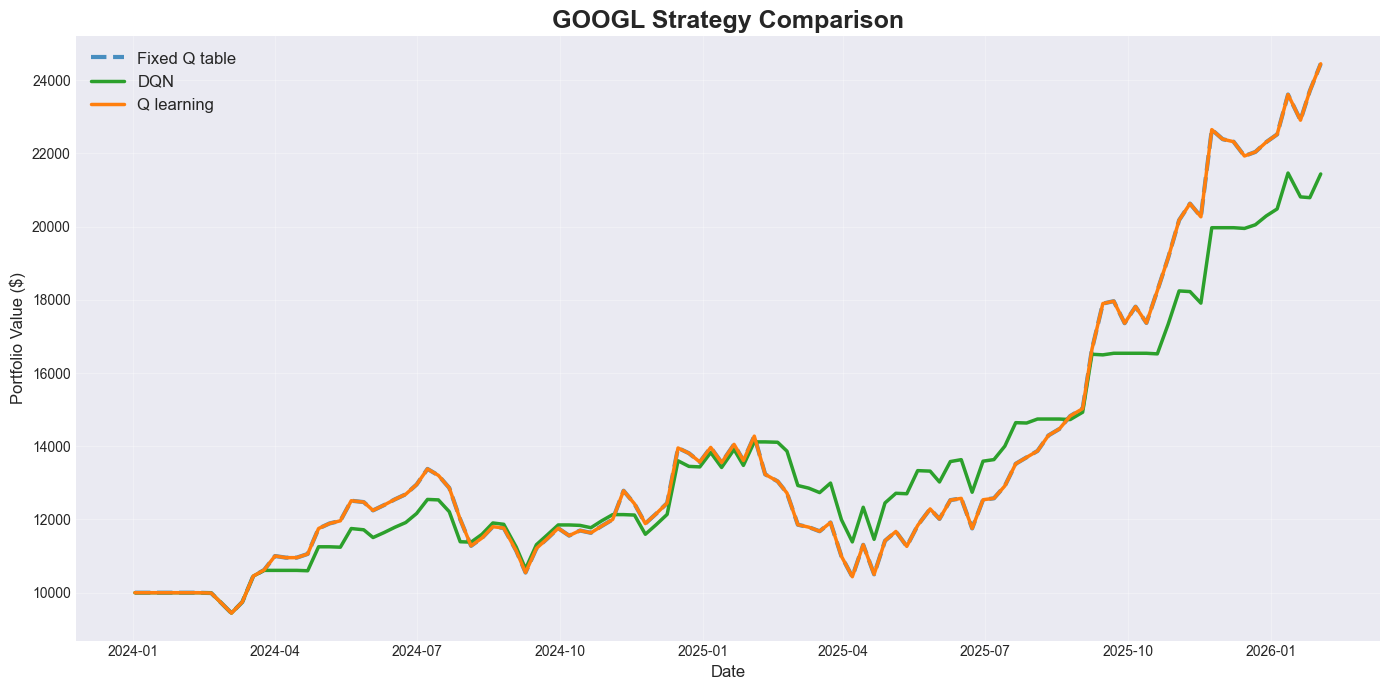

### 🧠 GOOGL Quarterly LLM Insights

**2024-02-20**: 1) **Revenue and Growth Trajectory**  
Alphabet exited 2023 with clear re-acceleration in core monetization: Google Services revenue reached **$76B (+12% YoY)**, led by **Search & Other (+13%)** and **YouTube Ads (+16%)**, partially offset by **Network (-2%)**. A notable mix shift continues toward higher-growth, more durable lines: **Subscriptions** scaled to **$15B annual revenue** (5x since 2019), while **Google Cloud surpassed $9B in Q4 revenue** with “accelerated growth” tied to GenAI demand. Recurring pattern: strength concentrates in first-party surfaces (Search/YouTube) while third-party network remains structurally pressured.

2) **Macro Environment Impact**  
With **inflation ~4.1%**, **unemployment ~3.8%**, and restrictive rates (**Fed funds 5.33%, 10Y 4.44%**), advertisers remain ROI-focused (“do-more-with-less”). This favors performance formats and measurable conversions—supporting Search and DR-driven YouTube—while brand budgets can be more cyclical.

3) **Key Business Drivers and Catalysts**  
Primary catalysts are **AI-driven product upgrades** (Gemini, SGE latency -40%), **ads automation** (Performance Max, Automatically Created Assets, Gemini-powered conversational campaign creation), and **Cloud GenAI stack** (Vertex AI adoption ~6x API growth from H1 to H2; Duet AI traction). Subscriptions (YouTube Premium/Music, TV, Google One nearing 100M) add recurring revenue.

4) **Risk Factors and Headwinds**  
Key risks include **SGE monetization/execution** (UX changes could disrupt query economics), **elevated AI/compute capex**, ongoing **Network declines**, and macro-driven budget volatility. Competitive pressure in GenAI and cloud pricing could compress margins.

5) **Forward-Looking Sentiment**  
Management tone is confidently constructive: “strong momentum” into 2024, with disciplined cost reengineering funding heavier AI investment. Recurring trend: sustained retail ad strength (notably **APAC since Q2’23**) and continued shift toward AI-enhanced performance advertising and enterprise AI workloads.

---

**2024-05-06**: 1) **Revenue and Growth Trajectory**  
Alphabet’s growth profile remains anchored in core ads with expanding contribution from newer engines. Management cited **Google Services revenue of ~$70B (+14% YoY)**, with **Search +14%** and **YouTube Ads +21%**, partially offset by **Network -1%**. A recurring pattern across periods is **scale plus reinvestment**: by 2025-Q3 total revenue reached **~$102.3B** with strong profitability (**net income ~$35.0B; EBITDA ~$49.7B**) and consistent EPS outperformance (**2025-Q3 reported $2.87 vs est. $2.32**), indicating operating leverage despite heavy AI spend.

2) **Macro Environment Impact**  
With **inflation ~2.95%** and **unemployment ~3.83%**, demand conditions look supportive for advertising, but **restrictive rates (Fed funds ~5.33%, 10Y ~4.16%)** can pressure marketing budgets and elongate enterprise procurement cycles. Alphabet’s performance suggests resilience, but cyclicality remains most visible in brand/network ads.

3) **Key Business Drivers and Catalysts**  
Primary catalysts are **AI-driven product upgrades** and monetization: AI Overviews/SGE rollout, **Gemini model cadence**, and **ads tooling (Gemini in Performance Max)** improving conversion outcomes. Cloud is positioned as the second pillar, with management targeting **YouTube + Cloud >$100B run-rate exiting 2024**, supported by AI infrastructure differentiation (TPUs/GPUs, “AI hypercomputer”).

4) **Risk Factors and Headwinds**  
Key headwinds include **elevated capex** (2025-Q3 **~$24B**, rising vs 2025-Q2 **~$22B**) pressuring near-term free cash flow, execution risk in Search UX changes (traffic quality, publisher ecosystem), intensifying AI competition, and ongoing regulatory scrutiny.

5) **Forward-Looking Sentiment**  
Tone is notably constructive: management emphasizes **measured SGE deployment**, improving **cost efficiency (SGE machine costs down ~80% vs early Labs)**, and multiple monetization paths (ads, cloud, subscriptions). Net: bullish on AI-led growth, tempered by investment intensity and policy/competitive risks.

---

...

---

**2025-11-03**: Alphabet delivered a step-change quarter with **revenue of $102.3B (+16% YoY)** and its first **$100B+ quarter**, extending a recurring pattern of **positive earnings surprises** (reported EPS **$2.87 vs. $2.32**). The growth trajectory is broad-based: **Google Services $87B (+14%)**, with **Search +15%** and **YouTube ads +15%**, while **Network revenues declined** again—an ongoing mix headwind. Profitability remains strong (operating income **$31.2B**, net income **$35.0B**), though operating expenses rose **28%** as AI-related R&D and depreciation scale.

Macro conditions are moderately restrictive: **Fed funds ~4.29%**, **10Y ~4.26%**, and **unemployment ~4.33%**. Higher rates typically pressure ad budgets and valuation multiples, but Alphabet’s results suggest **ad demand resilience**, especially in retail and financial services. Sticky inflation (CPI elevated) can support nominal ad spend, while also raising infrastructure and labor costs.

Key drivers/catalysts are clearly AI-led monetization and cloud demand. Management highlighted **AI Overviews/AI Mode driving incremental query growth** (AI Mode **75M DAUs**, queries doubled QoQ), and **AI Max for Search** as a fast-scaling ads product unlocking “billions of net new queries.” In Cloud, **backlog jumped 46% QoQ to $155B**, signaling durable forward revenue, while subscriptions surpassed **300M paid**.

Headwinds include **rising capex** (Q3 **$24.0B**, up from Q2 **$22.4B**) and higher depreciation/content costs, plus regulatory risk (notably a **$3.5B EU fine**). Forward sentiment is bullish: management frames Search as in an “expansionary moment,” Cloud AI demand as accelerating, and continued heavy investment in TPU/GPU capacity as necessary to meet demand.

---

**2026-02-02**: No data available for this quarter.

---

In [31]:
plot_ticker('GOOGL')

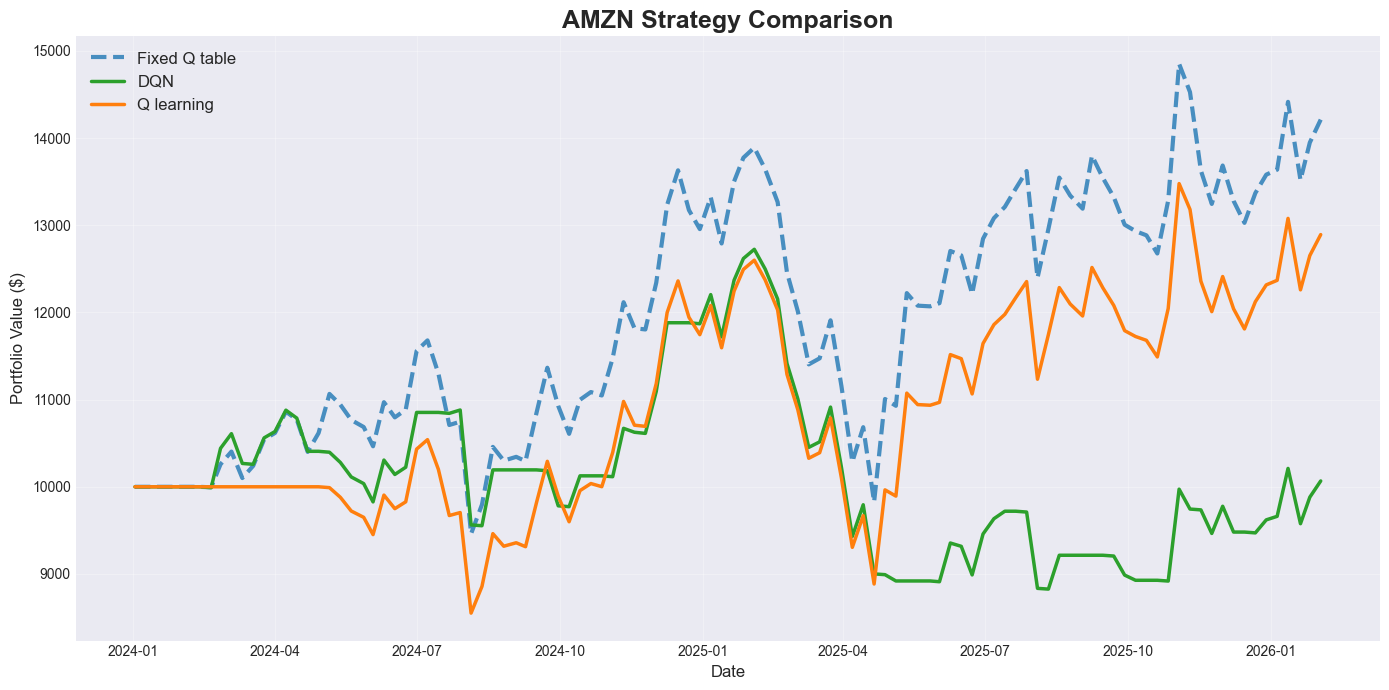

### 🧠 AMZN Quarterly LLM Insights

**2024-02-20**: No data available for this quarter.

---

**2024-05-06**: 1) **Revenue and Growth Trajectory**  
AMZN delivered **$143.3B Q1’24 revenue (+13% YoY ex-FX)**, reflecting resilient demand across Stores, Advertising, and re-accelerating AWS. A recurring pattern across subsequent quarters is **profit and cash flow scaling alongside heavy reinvestment**: by 2025-Q3, revenue reached **$180.2B** with **operating income $17.4B** and **net income $21.2B**, while capex remained elevated (**$35.1B**), signaling sustained build-out rather than margin harvesting alone.

2) **Macro Environment Impact**  
With **inflation ~2.95%**, **unemployment ~3.83%**, and a restrictive **Fed funds rate ~5.33%**, consumers are value-seeking—management explicitly notes **trade-down and deal sensitivity**. Higher rates also pressure enterprise budgets, but AWS commentary suggests optimization cycles are maturing, enabling spend to shift back toward growth initiatives (notably AI).

3) **Key Business Drivers and Catalysts**  
Key catalysts are (a) **logistics regionalization** and inbound architecture changes lowering cost-to-serve while improving speed, (b) **Advertising (+24% YoY ex-FX)** with upside from **Prime Video ads**, and (c) **AWS re-acceleration (17.2% YoY)** driven by modernization and a multi-layer **genAI stack** (Trainium/Inferentia, SageMaker, Bedrock, Amazon Q). A recurring trend is Amazon using **experience improvements (faster delivery)** to lift **purchase frequency** and basket size.

4) **Risk Factors and Headwinds**  
Risks include prolonged consumer caution, FX/geopolitical volatility, and execution risk in fulfillment network redesign. In AWS, competitive AI pricing and capacity constraints (timing of **Trainium2** supply) could affect growth and margins. Elevated capex and negative investing cash flow (e.g., **2025-Q3 -$26.1B**) increase sensitivity to demand shocks.

5) **Forward-Looking Sentiment**  
Management tone is constructive: efficiency gains are translating into sharply higher operating income and **surging trailing FCF**, while AWS demand is pivoting from optimization to innovation—suggesting improving growth quality into 2H’24/2025 if macro conditions remain stable.

---

...

---

**2025-08-04**: **1. Revenue and Growth Trajectory**  
AMZN delivered **$167.7B revenue (+12% YoY ex-FX)** in 2025-Q2, with **operating income $19.2B (+31% YoY)**, signaling margin-led scaling rather than purely volume-led growth. A recurring pattern across recent quarters is **strong profitability and cash generation alongside elevated reinvestment**: by 2025-Q3, operating cash flow reached **$35.5B** with **capex still very high (~$35.1B)**, implying Amazon is sustaining growth while funding logistics and AI infrastructure.

**2. Macro Environment Impact**  
With **Fed funds ~4.33%** and **10Y ~4.36%**, higher rates raise discount rates and can pressure consumer discretionary spend, but Amazon’s mix benefits from trade-down behavior (value/essentials) and resilient B2B cloud demand. Management noted **no meaningful demand degradation or price inflation yet** despite tariff noise—suggesting near-term macro drag is muted, though policy risk remains.

**3. Key Business Drivers and Catalysts**  
Recurring drivers: (a) **delivery speed + cost-to-serve improvements** (regionalized network, more direct lanes, fewer touches), (b) **Ads momentum** (**$15.7B, +22% YoY**) with DSP partnerships (Roku, Disney) expanding CTV reach, and (c) **AWS re-acceleration** (**+17.5% YoY; $123B run-rate**) powered by GenAI capacity (Trainium2, NVIDIA instances) and higher-layer services (Bedrock AgentCore, Transform, Kiro).

**4. Risk Factors and Headwinds**  
Key headwinds: **tariff pass-through uncertainty**, **AI capacity constraints** (“more demand than supplied”), sustained **capex intensity**, and potential consumer softness if unemployment rises from **4.2%**.

**5. Forward-Looking Sentiment**  
Tone is constructive: management emphasizes measurable operational efficiency gains and strong Prime Day performance. The recurring trend is **execution-driven margin expansion** while investing aggressively in **AI + logistics**, positioning AMZN for continued operating leverage if macro conditions stay stable.

---

**2025-11-03**: 1) **Revenue and Growth Trajectory**  
Amazon delivered **$180.2B revenue** in Q3’25, **+12% YoY ex-FX**, signaling broad-based acceleration versus the more muted growth profile seen in prior quarters. Profitability remained strong: **operating income $17.4B** (would have been **>$21B** excluding one-time items), with **net income $21.2B** and **EBITDA $45.5B**. A recurring pattern is **earnings outperformance** (reported **EPS $1.95 vs. $1.54 est.**) alongside continued reinvestment—**capex rose to $35.1B** from $32.2B in Q2, consistent with Amazon’s “invest through the cycle” playbook.

2) **Macro Environment Impact**  
With **Fed funds ~4.29%** and **10Y ~4.26%**, higher rates raise discount rates and can pressure consumer discretionary spend, but Amazon’s mix (essentials, ads, AWS) provides ballast. **Unemployment ~4.33%** suggests a still-resilient consumer, supporting retail volumes, while elevated CPI levels keep value-seeking behavior high—an Amazon tailwind if it maintains price leadership.

3) **Key Business Drivers and Catalysts**  
The core catalyst is **AWS reacceleration to 20.2% YoY** (fastest in 11 quarters) with **$200B backlog**, driven by AI adoption (Bedrock, AgentCore) and aggressive capacity buildout (power, Trainium/NVIDIA). **Ads grew 22% YoY to $17.6B**, aided by DSP expansion (Roku/Netflix/Spotify/SiriusXM) and Prime Video sports monetization. Retail catalysts include faster delivery, rural network expansion, and AI shopping tools (Rufus) tied to conversion uplift.

4) **Risk Factors and Headwinds**  
Key headwinds include **regulatory/legal exposure** (FTC settlement), restructuring costs, and execution risk from **very high capex** and AI capacity scaling. Consumer demand could soften if rates stay restrictive longer. Competitive intensity in cloud/AI and ad tech remains elevated.

5) **Forward-Looking Sentiment**  
Management tone is notably bullish on **AWS/AI monetization**, emphasizing that new capacity is being **rapidly monetized** and that October deal activity exceeded Q3 levels—suggesting momentum into Q4, albeit with continued heavy investment and policy/regulatory overhang.

---

In [32]:
plot_ticker('AMZN')

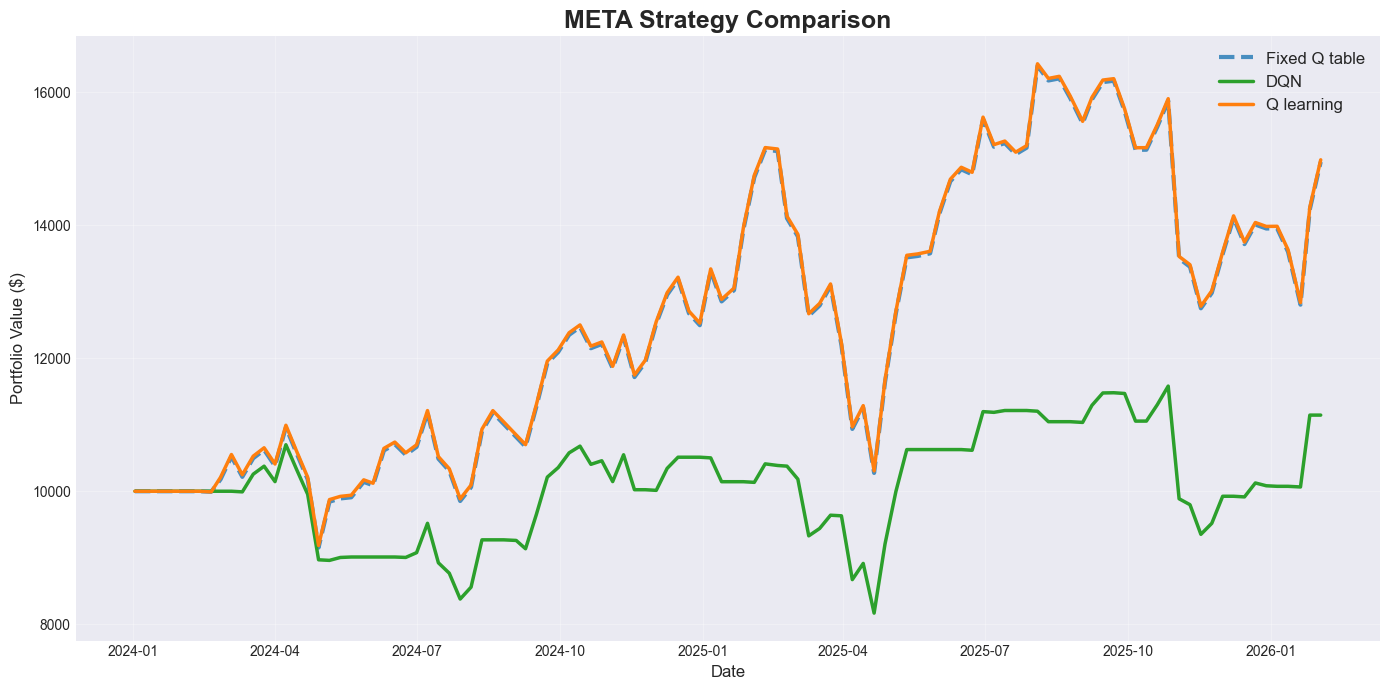

### 🧠 META Quarterly LLM Insights

**2024-02-20**: ### 1) Revenue and Growth Trajectory  
Meta exited 2023-Q4 with “returned to strong revenue growth” driven by engagement and improving ad performance, while 2025 data show the growth model has been paired with materially higher investment intensity. By 2025-Q4, revenue reached **$59.9B** with **net income $22.8B** and **EBITDA $31.5B**, alongside a continued pattern of **EPS beats** (reported **$8.88** vs est. **$8.22**). A recurring trend is Meta’s ability to expand earnings even while scaling major spend cycles—suggesting operating leverage in the core Ads business.

### 2) Macro Environment Impact  
In 2023-Q4, inflation (~**4.1%**) and a restrictive policy backdrop (Fed funds **5.33%**, 10Y **4.44%**) typically pressure ad budgets and valuation multiples. However, low unemployment (**3.8%**) and positive real GDP support consumer activity, helping performance advertising. Higher rates also raise the hurdle rate for long-duration bets (AI/metaverse), increasing investor sensitivity to CapEx and payback timelines.

### 3) Key Business Drivers and Catalysts  
Primary drivers: AI-driven ad ranking/targeting, Reels engagement, and messaging monetization (business AIs across WhatsApp/Messenger/IG). Catalysts include scaling **Llama** ecosystem (open-source as a distribution moat), rollout of Meta AI/Creator AIs, and hardware traction (Reality Labs >**$1B** revenue quarter; Ray-Ban Meta demand).

### 4) Risk Factors and Headwinds  
A clear recurring headwind is **rising CapEx** (2025-Q4 **$21.4B**) and heavy investing cash outflows, tied to GPU/data center buildouts—execution risk if monetization lags. Additional risks: ad-cycle sensitivity, regulatory/privacy constraints, and Reality Labs profitability drag despite revenue milestones.

### 5) Forward-Looking Sentiment  
Management tone is strongly “play to win” on AI infrastructure and general intelligence, implying sustained elevated investment. Near-term sentiment is constructive (product velocity, engagement, monetization pathways), but forward returns hinge on proving durable AI monetization and keeping spend growth from outpacing core Ads cash generation.

---

**2024-05-06**: 1) **Revenue & Growth Trajectory**  
META’s Q1’24 revenue of **$36.5B (+27% YoY)** reflects a strong re-acceleration in the core advertising engine, driven by **+20% ad impressions** and **+6% price**. This mix suggests both demand recovery and improved monetization efficiency. A recurring pattern across periods is META’s willingness to **absorb near-term margin/cash flow volatility** to scale new surfaces (e.g., Stories/Reels historically; now AI), then monetize once engagement stabilizes—management explicitly flags this playbook again. Longer-dated context (2025) shows **very high CapEx** levels, consistent with a sustained infrastructure buildout.

2) **Macro Environment Impact**  
With **inflation ~2.95%**, **unemployment ~3.83%**, and **policy rates ~5.33%**, the macro backdrop is “restrictive but stable.” Higher rates can pressure ad budgets and valuation multiples, but resilient labor and GDP support consumer activity and performance marketing. META’s broad advertiser base and measurable ROI tools help it hold up better than brand-heavy channels in tighter conditions.

3) **Key Business Drivers & Catalysts**  
Core drivers are (i) **AI-driven engagement and ranking** (now >50% of Instagram content AI-recommended), (ii) **AI-powered ad products** (Advantage+ revenues **>2x YoY**), and (iii) **WhatsApp U.S. momentum** plus business messaging optionality. Catalysts include broader rollout of **Meta AI (Llama 3)**, new ad/paid models inside AI interactions, and scaling **Ray-Ban Meta** / Horizon OS ecosystem.

4) **Risks & Headwinds**  
Primary headwinds: **multi-year AI CapEx and energy cost ramp**, monetization lag (explicitly acknowledged), legal/regulatory costs (G&A up **20%**), and Reality Labs investment drag/segment optics. Ad-cycle sensitivity remains a macro risk.

5) **Forward-Looking Sentiment**  
Management tone is confident but clear: expect a **prolonged investment cycle** before full AI monetization—mirroring prior transitions—while maintaining “efficiency” discipline to protect core profitability.

---

...

---

**2025-11-03**: 1) **Revenue and Growth Trajectory**  
Meta delivered strong top-line momentum in 2025-Q3 with **total revenue of $51.2B (+26% YoY)**, led by **Family of Apps ad revenue of $50.1B (+26%)**. Growth was balanced across volume and pricing: **ad impressions +14%** and **price per ad +10%**, signaling both engagement expansion and improved monetization. A recurring pattern is that **AI-driven ranking/recommendation upgrades translate into higher engagement, which then lifts impressions and pricing power**. Reality Labs revenue grew **+74% YoY** off a low base, aided by channel inventory build and AI glasses.

2) **Macro Environment Impact**  
With **Fed funds ~4.29%** and **10Y ~4.26%**, discount rates remain a valuation headwind for long-duration “AI infrastructure” spending stories, but Meta’s ad business is holding up well despite a still-moderate **4.33% unemployment** backdrop. Stable labor conditions support advertiser demand; higher rates mainly pressure capital intensity scrutiny rather than near-term demand.

3) **Key Business Drivers and Catalysts**  
Core catalysts are (a) **recommendation quality** (time spent +5% Facebook; Threads +10%), (b) **video/Reels monetization** (Reels **>$50B annual run-rate**), (c) **AI-powered ad stack** (**>$60B annual run-rate** through end-to-end tools), and (d) emerging monetization from **WhatsApp paid messaging** and subscriptions. Hardware (AI glasses) is an incremental upside vector.

4) **Risk Factors and Headwinds**  
Recurring headwind: **expense growth outpacing revenue** near-term (**expenses +32% YoY**) driven by AI talent, depreciation, and cloud. **CapEx is structurally rising** (Q3 **$19.4B**; Q4 historical **$21.4B**), increasing execution risk if AI ROI timelines slip. One-time tax impacts created earnings noise (Q3 GAAP tax rate **87%**). Regulatory/legal costs also re-accelerated.

5) **Forward-Looking Sentiment**  
Management is explicitly **front-loading compute** for “superintelligence” scenarios while arguing downside is manageable via slower build later—overall **bullish**, with 2026 focus on foundational ranking models and LLM-based content understanding as the next engagement/monetization step-change.

---

**2026-02-02**: ### 1) Revenue and Growth Trajectory  
Meta delivered a strong Q4 with total revenue of **$59.9B** and Family of Apps revenue of **$58.9B (+25% YoY)**, driven primarily by advertising (**$58.1B, +24% YoY**). Growth is broad-based: **ad impressions +18%** and **price per ad +6%**, indicating both engagement-led inventory expansion and improved monetization. A recurring pattern across recent quarters is **AI-driven performance gains translating into higher conversion and pricing power**, reinforced by another **EPS beat (reported 8.88 vs. 8.22)**.  

### 2) Macro Environment Impact  
With unemployment at **4.45%** and policy rates near **3.9%** (10Y ~**4.1%**), the macro backdrop implies still-restrictive financing conditions but resilient demand. For Meta, the key sensitivity is **advertiser budgets**: stable labor markets support ad spend, while higher rates raise the hurdle for incremental capex—important given Meta’s heavy infrastructure build.  

### 3) Key Business Drivers and Catalysts  
Core catalysts are (i) **recommendation improvements** (Facebook organic views +7%; Threads time spent +20%), (ii) **AI upgrades to ads ranking and model unification** (e.g., runtime model +3% conversions; ad quality +12%), and (iii) **new monetization surfaces** (Threads ad expansion; WhatsApp ads/status rollout). “Other revenue” growth (**+54%**) from WhatsApp paid and MetaVerified adds diversification.  

### 4) Risk Factors and Headwinds  
Primary headwinds are **elevated capex** (Q4 **$21.4B**) and rising infrastructure depreciation/cloud costs, plus ongoing **Reality Labs revenue decline (-12% YoY)** and continued losses (management expects 2026 losses similar to 2025). Regulatory/legal expense volatility is also recurring.  

### 5) Forward-Looking Sentiment  
Management tone is notably bullish on **2026 AI acceleration**, with emphasis on agents, LLM-integrated recommendations, and AI commerce. The recurring strategic thread: **scale compute aggressively now to compound engagement and ad performance later**, while aiming for a gradual improvement in Reality Labs profitability over time.

---

In [33]:
plot_ticker('META')

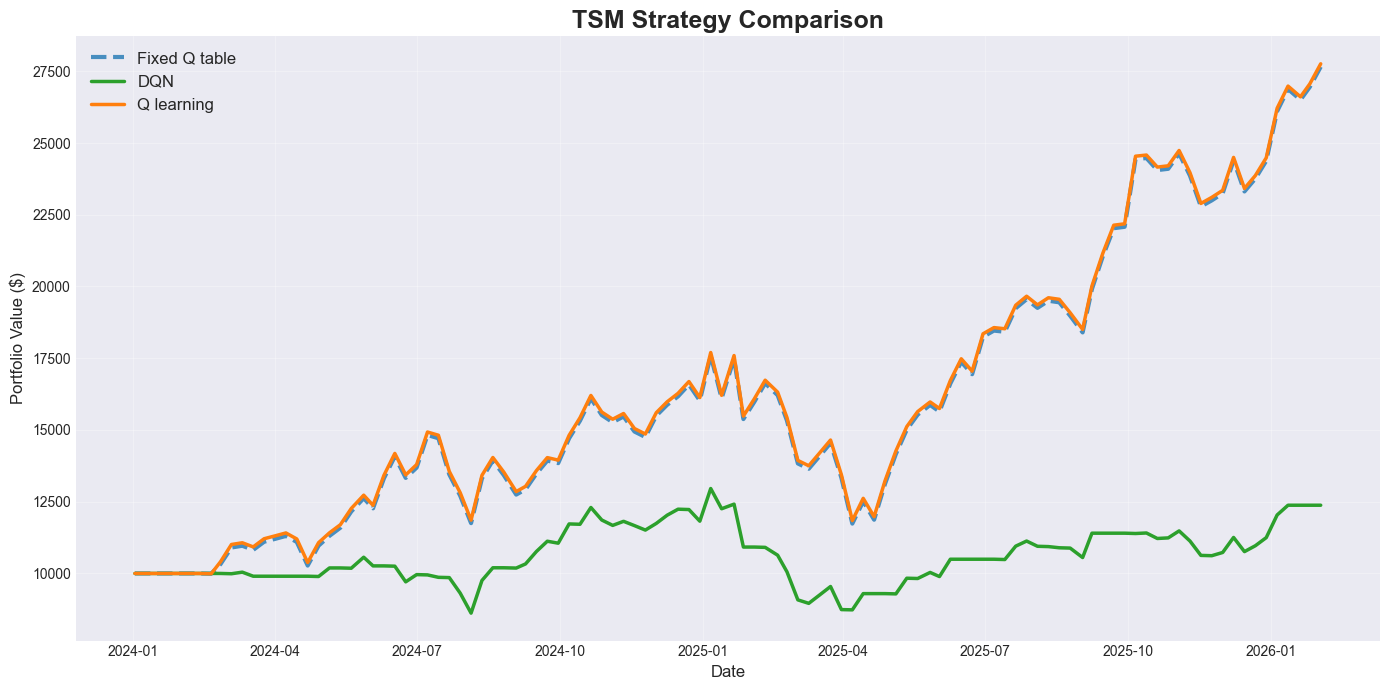

### 🧠 TSM Quarterly LLM Insights

**2024-02-20**: 1) **Revenue & Growth Trajectory**  
TSMC’s 4Q23 revenue rebounded **+13.6% QoQ (USD)**, driven by the **3nm ramp** and a recovery in key end markets. Management signaled a typical **1Q24 seasonal dip (~6% QoQ at midpoint)**, but expects **QoQ growth through 2024** and **low-to-mid 20% FY24 USD revenue growth**, implying a clear inflection from 2023’s downcycle (FY23 revenue **-8.7% YoY**). A recurring pattern emerges: **leading-edge node ramps (N3) lift revenue first, while margins lag** due to early ramp costs.

2) **Macro Environment Impact**  
With **Fed funds ~5.33%** and inflation still elevated (~**4.1%**), tighter financial conditions pressure consumer electronics demand (smartphone/IoT), consistent with management’s comment that macro weakness prolonged the inventory correction. However, low unemployment (~**3.8%**) and stabilizing inventories support a 2024 recovery. Higher rates also raise hurdle rates for customer capex, reinforcing the importance of AI/HPC’s structural demand.

3) **Key Drivers & Catalysts**  
Primary catalysts are **N3/N3E scaling** (3nm to **mid-teens wafer revenue mix in 2024**, “more than triple” revenue) and **AI/HPC strength** (HPC **43% of revenue** in 4Q23 and FY23). Continued **advanced-node mix expansion** (7nm and below **67%** in 4Q23) and **advanced packaging investment** further support AI accelerators.

4) **Risks & Headwinds**  
Near-term headwinds: **gross margin dilution** from N3 ramp (**-3 to -4 pts in 2024**) plus **tool conversion impacts** (additional **-1 to -2 pts** in 2H24), FX sensitivity, and lingering geopolitical uncertainty. Demand risk remains concentrated in cyclical smartphone/consumer segments.

5) **Forward-Looking Sentiment**  
Management tone is constructive: the business has **“bottomed” YoY**, inventories are healthier, and AI engagement is accelerating into **N2**, suggesting a multi-year growth runway. Recurring trend: **capex leads growth**—TSMC continues heavy investment (2024 capex **$28–$32B**, 70–80% advanced nodes), positioning for sustained share gains as the foundry cycle turns.

---

**2024-05-06**: ### 1) Revenue and Growth Trajectory  
TSMC’s 1Q24 revenue of **$18.9B** came in slightly above guidance but declined sequentially (**-3.8% USD**) due to **smartphone seasonality**, partially offset by **HPC strength** (HPC **46%** of revenue, +3% QoQ). Management guided **2Q24 revenue to $19.6–$20.4B** (~**+6% QoQ**, **+27.6% YoY** at midpoint), signaling a near-term re-acceleration driven by **3nm/5nm** demand. A recurring pattern is clear: **seasonal smartphone softness** pressures quarterly revenue mix, while **HPC provides a stabilizing counterweight**. Longer-term, historical data (2025) shows a **scale-up in revenue and earnings power** alongside **elevated CapEx**, consistent with sustained advanced-node demand.

### 2) Macro Environment Impact  
With **policy rates ~5.33%** and **10Y ~4.16%**, tighter financial conditions can weigh on consumer electronics (smartphones/PCs), reinforcing management’s “moderate and gradual” market recovery view. However, **AI/HPC capex cycles** are less rate-sensitive, supporting TSMC’s advanced-node utilization. Inflation near **~3%** and low unemployment suggest resilient demand, but geopolitics remains a swing factor.

### 3) Key Business Drivers and Catalysts  
Catalysts include **3nm ramp (9% of wafer revenue in 1Q)**, continued **5nm leadership**, and **HPC/AI-driven wafer demand**. Mix shift toward leading-edge nodes is the core growth engine, supported by tool conversions from **5nm to 3nm** to meet “strong multiyear demand.”

### 4) Risk Factors and Headwinds  
Near-term headwinds are **margin dilution**: earthquake-related scrap (**~50 bps** GM hit in 2Q), **Taiwan electricity price +25%** (another **70–80 bps** hit in 2Q; **60–70 bps** ongoing), and structurally lower margins from **3nm dilution (3–4 pts in 2H24)** plus **tool conversion (1–2 pts)**. Inventory days rising (to **90**) also signals ramp-related working-capital drag.

### 5) Forward-Looking Sentiment  
Management remains constructive: 2H24 expected stronger than 1H24, and they reiterate **long-term GM ≥53%** achievable via pricing/value capture and cost improvements. Sentiment is bullish on **AI/HPC and advanced nodes**, tempered by recurring themes of **smartphone cyclicality**, **cost inflation**, and **macro/geopolitical uncertainty**.

---

...

---

**2025-11-03**: 1) **Revenue & Growth Trajectory**  
TSMC delivered a clear re-acceleration in 2025, with **Q3 revenue up 10.1% QoQ to $33.1B** on strong leading-edge demand, and **Q4 guided to $32.2–$33.4B** (roughly flat QoQ at the midpoint, but **+22% YoY**). A recurring pattern across recent quarters is **growth being led by advanced nodes**: in Q3, **7nm-and-below was 74%** of wafer revenue, with **3nm at 23%** and **5nm at 37%**, reinforcing a sustained mix shift toward premium technologies that supports pricing and utilization.

2) **Macro Environment Impact**  
With **policy rates ~4.3%** and elevated yields, consumer electronics demand remains more rate-sensitive; management explicitly flags **tariff-policy uncertainty** as a risk for **price-sensitive, consumer-related segments**. However, the macro drag is being offset by **structural AI/HPC demand**, which is less cyclical and more capacity-constrained.

3) **Key Drivers & Catalysts**  
Primary catalysts are **AI-driven HPC silicon**, continued **3nm/5nm strength**, and the **N2 ramp** (volume production later in Q4) with **N2P and A16** slated for 2H26. Another recurring driver is **scale-enabled margin resilience** despite overseas expansion. **CapEx raised/narrowed to $40–$42B** (70% advanced nodes; 10–20% advanced packaging), signaling confidence in multi-year demand.

4) **Risks & Headwinds**  
Key headwinds include **overseas fab margin dilution** (now seen ~2% in 2H25; structurally 2–4% over coming years), **FX sensitivity**, geopolitics/tariffs, and execution risk on rapid node transitions and global footprint buildout.

5) **Forward-Looking Sentiment**  
Management tone is notably constructive: **AI conviction is “strengthening,”** non-AI markets are **bottoming with mild recovery**, and FY25 revenue is expected to grow **mid-30s% YoY**—tempered by prudence into 2026 given policy uncertainty.

---

**2026-02-02**: ### 1. Revenue and Growth Trajectory  
TSMC delivered a strong 2025-Q4 with total revenue of **~TWD 1.056T**, supported by **leading-edge demand** and improving profitability (gross margin **62.3%**, operating margin **54%**). A recurring pattern across 2025 is **outsized growth versus the broader “Foundry 2.0” market**: management cites **+35.9% USD revenue growth in 2025** versus **+16%** industry growth, driven by advanced-node mix and high utilization. Node mix continues to shift up the curve: **7nm-and-below reached 77% of wafer revenue** (up from 69% in 2024), with **3nm at 28% in Q4**—a durable mix tailwind. Q1’26 guidance implies **~4% QoQ** and **~38% YoY** growth at the midpoint, reinforcing momentum.

### 2. Macro Environment Impact  
With policy rates near **3.9%** and the 10Y around **4.1%**, higher discount rates can pressure equity multiples and raise hurdle rates for customers, but TSMC’s demand is currently **less cyclical** due to AI/HPC. Uncertainty around **tariffs and component price inflation** is flagged as a risk, particularly for consumer/price-sensitive segments.

### 3. Key Business Drivers and Catalysts  
Primary drivers are **AI/HPC (55% of Q4 revenue; +48% YoY in 2025)**, accelerating **3nm ramp**, and expanding **advanced packaging**. Catalysts include **N3 margin crossover to corporate average in 2026**, rising utilization, and **2026 CapEx of $52–56B** (70–80% to advanced nodes), positioning for multi-year AI capacity needs.

### 4. Risk Factors and Headwinds  
Recurring headwinds: **margin dilution from overseas fabs** (guided **2–4%** over time) and **N2 ramp dilution** (another **2–3%** in 2026), plus FX sensitivity. Execution risk rises with the step-up in CapEx and high-teens depreciation growth.

### 5. Forward-Looking Sentiment  
Management tone is constructive: expects **~30% USD revenue growth in 2026** and continued outperformance, while emphasizing prudence on tariffs/consumer softness. The consistent trend is **AI-led strength offsetting weaker non-AI cyclicality**, with profitability defended via productivity gains, cross-node optimization, and “strategic” pricing.

---

In [34]:
plot_ticker('TSM')

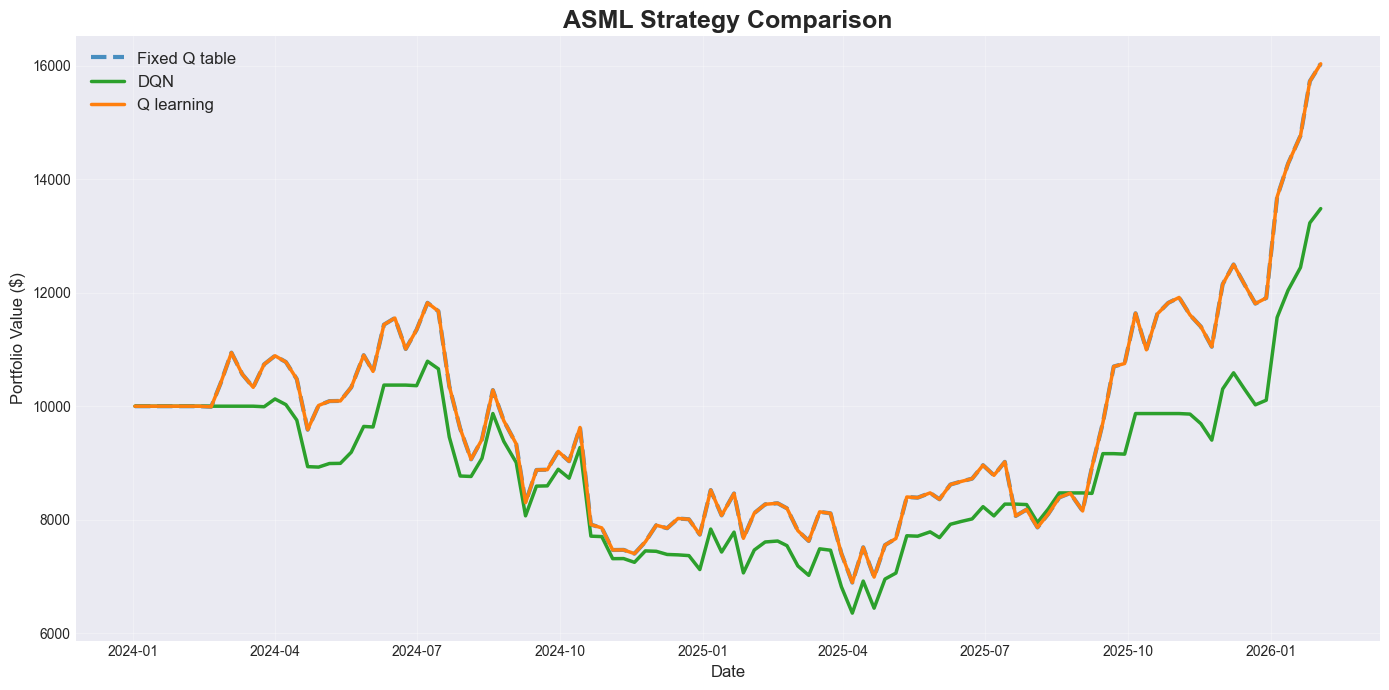

### 🧠 ASML Quarterly LLM Insights

**2024-02-20**: ### 1) Revenue and Growth Trajectory  
ASML exited 2023 with strong momentum: Q4 net sales were €7.2B (above guidance) and FY23 revenue grew 30% to €27.6B, supported by EUV (+30%) and especially DUV/DPV (+60%). A recurring pattern is **cyclical volatility in quarterly revenue/margins** driven by shipment timing and mix: management guided a notably softer Q1’24 (€5.0–€5.5B; 48–49% GM) after a strong Q4 (51.4% GM). Another recurring trend is **bookings strength preceding revenue inflection**—Q4 bookings were €9.2B and backlog ended at €39B, reinforcing visibility despite near-term digestion.

### 2) Macro Environment Impact  
With CPI/inflation still elevated and policy rates restrictive (Fed 5.33%, 10Y 4.44%), semiconductor capex remains cautious, extending the “transition year” framing for 2024. Higher rates can delay fab build-outs, but ASML’s backlog and strategic tool scarcity partially insulate demand.  

### 3) Key Business Drivers and Catalysts  
Primary catalysts are **AI-driven logic and memory demand** (HBM/DDR5 node transitions), **higher EUV ASPs** (NXE:3800E mix skewing to 2H), and **installed base upgrades/services** (a recurring margin stabilizer). High-NA introductions (first 1–2 systems revenue in 2024; broader 2025 ramp) are a major multi-year driver.

### 4) Risk Factors and Headwinds  
Key headwinds include **export controls to China** (10–15% of 2023 China system revenue impact), **2024 mix pressure** (lower immersion/DPV mix), and **ramp costs** tied to capacity expansion and High-NA, which management expects to depress 2024 gross margin vs. 2023.

### 5) Forward-Looking Sentiment  
Management tone is cautiously constructive: 2024 revenue expected roughly flat vs. 2023, with a **stronger 2H** and a **pronounced 2025 upcycle** supported by secular AI/electrification and new fab build-outs. The recurring setup is “soft near-term, invest through the trough, accelerate into the next node-driven upturn.”

---

**2024-05-06**: ### 1. Revenue and Growth Trajectory  
ASML’s 2024-Q1 net sales were **€5.3B** (in-line with guidance), with **systems €4.0B** and **Installed Base Management (IBM) €1.3B**. EUV remains central: **12 EUV shipped** with **€1.8B recognized** (11 systems). Management reiterated **2024 revenue roughly flat vs. 2023**, but with a **back-half weighted recovery**. A recurring pattern in ASML’s cycle is **lumpy bookings and revenue timing** (explicitly noted again this quarter), with demand inflecting after utilization improves; this is consistent with the “slow start/stronger second half” framing. The **~€38B backlog** provides multi-quarter visibility and supports the 2025 ramp narrative.

### 2. Macro Environment Impact  
With **policy rates ~5.33%** and still-elevated yields, customer financing discipline is high; ASML cited **lower down payments** and customer focus on **cash/profitability**, contributing to **negative free cash flow** and higher inventory. Moderating inflation (~2.95%) and low unemployment support end-demand resilience, but capex decisions remain gated by semiconductor profitability and utilization rather than broad GDP alone.

### 3. Key Business Drivers and Catalysts  
Primary catalysts are **AI-driven compute demand**, **DRAM transitions (DDR5/HBM)**, and the **NXE:3800E** ramp (higher productivity/ASP/margins). **High-NA EUV** (1–2 systems revenue in 2024) is a strategic inflection for sub-2nm logic and advanced DRAM, reinforcing long-duration growth.

### 4. Risk Factors and Headwinds  
Headwinds include **logic digestion** after prior capacity adds, **non-EUV weakness** (down in 2024), and **working-capital pressure** from inventory build for High-NA capacity. Order volatility remains a recurring feature, and macro/geopolitical uncertainty can affect customer timing.

### 5. Forward-Looking Sentiment  
Tone is constructive: management believes the industry is **past the bottom**, expects **2025 to be strong**, and is investing through the cycle. The message is consistent with prior cycles: **utilization recovery → upgrade/transition spending → tool demand acceleration**, with ASML positioned to capture both cyclical upturn and secular node complexity.

---

...

---

**2025-11-03**: 1) **Revenue and Growth Trajectory**  
ASML’s growth profile remains “lumpy but planned,” with Q3 net sales of **€7.5B** (including **one High-NA** recognition) and management guiding a seasonally strong **Q4 at €9.2–€9.8B**, mirroring the recurring pattern of outsized Q4 deliveries seen in **2024** and reiterated for **2025**. Installed base revenue is a steady ballast (**€2.0B in Q3; ~€2.1B guided in Q4**), helping smooth system shipment cyclicality. Bookings of **€5.4B** (with **€3.6B EUV**) support continued advanced-node demand.

2) **Macro Environment Impact**  
With policy rates ~**4.3%** and yields ~**4.26%**, financing costs stay elevated, typically pressuring broad capex. However, ASML’s demand is less rate-sensitive near-term because leading-edge spend is being structurally pulled forward by **AI-driven logic and advanced DRAM**. The key macro/geopolitical swing factor is **China**, where management expects materially lower demand in **2026** versus the unusually strong **2024–2025** period.

3) **Key Business Drivers and Catalysts**  
Primary catalysts are rising **litho intensity**, expanding **EUV adoption in DRAM**, and accelerating **High-NA maturity** (300k wafers run; early customer validation). New adjacency upside comes from **advanced packaging/3D integration** (first XT260 shipped; broader customer interest) and software leverage via the **Mistral AI partnership** to shorten development cycles.

4) **Risk Factors and Headwinds**  
Main headwinds: a **2026 China step-down** (especially **DUV** mix), shipment timing/acceptance volatility (driving EPS variability), and execution risk scaling High-NA and new packaging tools. Persistent high rates could still delay non-leading-edge capacity adds.

5) **Forward-Looking Sentiment**  
Management tone is constructive: **2026 net sales “not below 2025”**, mix shifting toward **UV/EUV**, and a reiterated **€44–€60B 2030** revenue opportunity with **56–60%** gross margin—signaling confidence that AI and new product vectors can offset regional softness.

---

**2026-02-02**: ### 1) Revenue and Growth Trajectory  
ASML exited 2025 with a clear re-acceleration: Q4 revenue was **$8.43B** with **record bookings**, and FY2025 net revenue reached **€32.7B** at a **52.8% gross margin**. Profitability remained strong (Q4 operating income **$2.51B**, net income **$2.07B**), while operating cash flow was exceptionally high (**$11.0B**), supporting continued shareholder returns despite negative financing cash flow (buybacks/dividends). A recurring pattern across the narrative is **“uncertainty → late-year clarification → surge in orders/execution”**, culminating in a record Q4 that management frames as setting up 2026.

### 2) Macro Environment Impact  
With unemployment at **4.45%** and policy rates near **3.9%** (10Y ~**4.1%**), financing conditions are not easy, but ASML’s demand is being driven less by consumer cyclicality and more by **strategic AI infrastructure capex**. Higher rates can delay fab decisions at the margin, yet current signals suggest customers are prioritizing capacity for AI-related nodes.

### 3) Key Business Drivers and Catalysts  
The dominant catalyst is **AI-driven capacity additions** across **advanced logic and advanced DRAM**. EUV is the primary growth engine (FY EUV revenue up **39% YoY**), boosted by the richer mix of **higher-productivity 3800 systems** and initial **High-NA (EXE)** recognition. A second, recurring stabilizer is the expanding **installed base business (€8.2B)**, which adds resilience via service, upgrades, and productivity enhancements. Emerging upside includes **3D integration** (XT:260 shipment, strong customer interest).

### 4) Risk Factors and Headwinds  
Key risks include: (1) **capex digestion/cycle risk** if AI demand normalizes, (2) **execution and ramp complexity** for EUV/High-NA volumes, (3) **organizational restructuring in D&E** (even if charges are “not material,” disruption risk exists), and (4) potential **geopolitical/export constraint** sensitivity (implied by prior China/backlog commentary).

### 5) Forward-Looking Sentiment  
Management tone is notably constructive: the last three months “clarified” 2026 visibility, with expectations to **ship more EUV tools** and expand manufacturing/customer service headcount. The long-term framework (**€44B–€60B revenue**) remains intact, implying confidence that AI is translating into sustained tool demand rather than transient capex inflation.

---

In [35]:
plot_ticker('ASML')